# Workshop 9 — Fine-tune TrOCR with traceable evidence

**Historical experiment record.** Open-phase and candidate-review statements below
describe the Workshop 9 handoff. For current adoption and source reuse, see the
[Phase 3 delivery record](../docs/phases/phase-3.md). Original experiment code,
outputs, and copied-definition provenance are retained unchanged.

The user delegated execution and documentation of this experiment. We adapt the
existing checkpoint, compare it with the untouched pretrained baseline, and
retain every selection result. **Phase 3 remains open; Workshop 10 is not run.**

The question: can supervised adaptation on readable training identity-field crops
reduce recurring errors in names, numbers, dates, nationality, and single-character
sex fields, without changing the scoring or preprocessing contract?

This notebook contains the complete executable experiment. It includes explicit
copies of previously tested pipeline/metric definitions, marked with provenance
hashes, rather than executing other notebooks with hidden side effects. No new
training framework or dependency is required. Read the explanations before the
cells; detailed concepts live in [the training guide](../docs/learning/ocr-finetuning.md)
and results in [the experiment report](../docs/experiments/ocr-finetuning.md).

The versioned [configuration](../configs/ocr_finetuning_v1.json) is read before
training. A fresh run gets its own artifact and checkpoint directories; existing
baseline results and checkpoints are preserved. Rerunning trains again, so review
the configuration and saved outputs before choosing Run All.

In [1]:
from pathlib import Path
import json

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

from transformers import (
    GenerationConfig,
    TrOCRProcessor,
    VisionEncoderDecoderModel,
)


current_directory = Path.cwd().resolve()

if (current_directory / "PROJECT.md").is_file():
    repository_root = current_directory
elif (current_directory.parent / "PROJECT.md").is_file():
    repository_root = current_directory.parent
else:
    raise FileNotFoundError(
        "Start Jupyter from the repository root or notebooks directory."
    )

dataset_root = repository_root / "data" / "raw"

print("Repository root:", repository_root)
print("Dataset root:", dataset_root)

/home/raspiestchip/kyc-router/.venv/lib64/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Repository root: /home/raspiestchip/kyc-router
Dataset root: /home/raspiestchip/kyc-router/data/raw


In [2]:
import copy
import gc
import hashlib
import importlib.metadata
import math
import os
import platform
import random
import subprocess
import time
from collections.abc import Mapping
from datetime import datetime, timezone
from IPython.display import Markdown, display
from torch.utils.data import Dataset, DataLoader
from transformers import get_linear_schedule_with_warmup
import psutil

config_path = repository_root / "configs" / "ocr_finetuning_v1.json"
experiment = json.loads(config_path.read_text())
run_id = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
artifact_directory = repository_root / "outputs" / "phase3_finetuning" / run_id
checkpoint_directory = repository_root / "checkpoints" / "phase3_finetuning" / run_id
artifact_directory.mkdir(parents=True, exist_ok=False)
checkpoint_directory.mkdir(parents=True, exist_ok=False)

def save_json(path, value):
    path.write_text(json.dumps(value, ensure_ascii=False, indent=2, allow_nan=False), encoding="utf-8")

def write_jsonl(path, rows):
    with path.open("w", encoding="utf-8") as stream:
        for row in rows:
            stream.write(json.dumps(row, ensure_ascii=False, allow_nan=False) + "\n")

def file_hash(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()

def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

assert torch.cuda.is_available(), "Run in the validated project environment with GPU access."
device = torch.device("cuda:0")
torch.set_num_threads(4)
cv2.setNumThreads(1)
torch.backends.cudnn.benchmark = False
seed_everything(experiment["seed"])
save_json(artifact_directory / "experiment_config.json", experiment)
print("Run:", run_id)
print("Artifacts:", artifact_directory)
print("Checkpoints:", checkpoint_directory)

Run: 20261012T230738117335Z
Artifacts: /home/raspiestchip/kyc-router/outputs/phase3_finetuning/20261012T230738117335Z
Checkpoints: /home/raspiestchip/kyc-router/checkpoints/phase3_finetuning/20261012T230738117335Z


In [3]:
phase_2_config_path = (
    repository_root
    / "configs"
    / "controlled_degradations_v1.json"
)

with phase_2_config_path.open(encoding="utf-8") as config_file:
    phase_2_config = json.load(config_file)

canonical_width = phase_2_config["canonical_width"]
canonical_height = phase_2_config["canonical_height"]

In [4]:
split_manifest_path = (
    repository_root
    / "splits"
    / "alb_id_v1.csv"
)

split_manifest = pd.read_csv(
    split_manifest_path,
    dtype={"sample_id": "string"},
)
split_counts = split_manifest["split"].value_counts()

assert len(split_manifest) == 100
assert split_manifest["identity_key"].is_unique
assert split_counts.to_dict() == {
    "train": 70,
    "validation": 15,
    "test": 15,
}

split_counts

split
train         70
validation    15
test          15
Name: count, dtype: int64

In [5]:
document_type = "alb_id"

raw_to_canonical_field = {
    "number": "document_number",
    "surname": "surname",
    "name": "given_names",
    "birth_date": "date_of_birth",
    "expiry_date": "expiry_date",
    "nationality": "nationality",
    "gender": "sex",
}

ocr_model_id = "microsoft/trocr-small-printed"
ocr_model_revision = (
    "04e994ab854b0089d4929f48c2b4dbe2ce78a340"
)

print("Required fields:", list(raw_to_canonical_field.values()))
print("OCR checkpoint:", ocr_model_id)
print("Revision:", ocr_model_revision)

Required fields: ['document_number', 'surname', 'given_names', 'date_of_birth', 'expiry_date', 'nationality', 'sex']
OCR checkpoint: microsoft/trocr-small-printed
Revision: 04e994ab854b0089d4929f48c2b4dbe2ce78a340


In [6]:
import unicodedata


def is_missing_scalar(value):
    if value is None:
        return True

    missing_result = pd.isna(value)

    return isinstance(
        missing_result,
        (bool, np.bool_),
    ) and bool(missing_result)


def normalize_common_text(value):
    if is_missing_scalar(value):
        return None

    text = unicodedata.normalize(
        "NFC",
        str(value),
    )

    text = " ".join(text.split())

    return text.casefold()

In [7]:
common_only_fields = frozenset(
    {
        "surname",
        "given_names",
        "nationality",
    }
)


def normalize_document_number(value):
    normalized_value = normalize_common_text(value)

    if normalized_value is None:
        return None

    without_whitespace = "".join(
        normalized_value.split()
    )

    return without_whitespace.upper()


def normalize_sex(value):
    normalized_value = normalize_common_text(value)

    if normalized_value is None:
        return None

    return normalized_value.upper()


def normalize_non_date_field(field_name, value):
    if field_name in common_only_fields:
        return normalize_common_text(value)

    if field_name == "document_number":
        return normalize_document_number(value)

    if field_name == "sex":
        return normalize_sex(value)

    raise ValueError(
        f"{field_name!r} is not a supported non-date field."
    )

In [8]:
import re
from datetime import datetime


supported_date_patterns = (
    (
        re.compile(r"^\d{2}-\d{2}-\d{4}$"),
        "%d-%m-%Y",
    ),
    (
        re.compile(r"^\d{2}/\d{2}/\d{4}$"),
        "%d/%m/%Y",
    ),
    (
        re.compile(r"^\d{2}\.\d{2}\.\d{4}$"),
        "%d.%m.%Y",
    ),
    (
        re.compile(r"^\d{4}-\d{2}-\d{2}$"),
        "%Y-%m-%d",
    ),
)


def parse_supported_date_text(normalized_text):
    for pattern, date_format in supported_date_patterns:
        if not pattern.fullmatch(normalized_text):
            continue

        try:
            return datetime.strptime(
                normalized_text,
                date_format,
            ).date()
        except ValueError:
            return None

    return None


def normalize_date(value):
    normalized_text = normalize_common_text(value)

    if normalized_text is None:
        return None

    parsed_date = parse_supported_date_text(
        normalized_text
    )

    if parsed_date is None:
        return normalized_text

    return parsed_date.isoformat()

In [9]:
date_fields = frozenset(
    {
        "date_of_birth",
        "expiry_date",
    }
)

required_field_names = tuple(
    raw_to_canonical_field.values()
)

assert len(required_field_names) == 7
assert len(set(required_field_names)) == 7


def normalize_field_value(field_name, value):
    if field_name not in required_field_names:
        raise ValueError(
            f"Unknown canonical field: {field_name!r}"
        )

    if field_name in date_fields:
        return normalize_date(value)

    return normalize_non_date_field(
        field_name,
        value,
    )


def normalize_document_values(
    field_values,
    required_fields,
):
    expected_fields = set(required_fields)
    received_fields = set(field_values)

    missing_fields = expected_fields - received_fields
    unexpected_fields = received_fields - expected_fields

    if missing_fields or unexpected_fields:
        raise ValueError(
            "Invalid document schema. "
            f"Missing: {sorted(missing_fields)}; "
            f"unexpected: {sorted(unexpected_fields)}."
        )

    return {
        field_name: normalize_field_value(
            field_name,
            field_values[field_name],
        )
        for field_name in required_fields
    }

In [10]:
canonical_date_pattern = re.compile(
    r"^\d{4}-\d{2}-\d{2}$"
)

alb_id_validation_config = {
    "document_number_pattern": re.compile(
        r"^\d{9}$"
    ),
    "allowed_nationalities": frozenset(
        {
            "shqiptare/albanian",
        }
    ),
    "allowed_sex_values": frozenset(
        {
            "M",
            "F",
        }
    ),
}


def parse_canonical_date(value):
    if not isinstance(value, str):
        return None

    if not canonical_date_pattern.fullmatch(value):
        return None

    try:
        return datetime.strptime(
            value,
            "%Y-%m-%d",
        ).date()
    except ValueError:
        return None

In [11]:
def validate_field_value(
    field_name,
    normalized_value,
    *,
    validation_config,
):
    if field_name not in required_field_names:
        raise ValueError(
            f"Unknown canonical field: {field_name!r}"
        )

    errors = []

    if is_missing_scalar(normalized_value):
        errors.append("missing_value")

        return {
            "is_valid": False,
            "errors": tuple(errors),
        }

    if not isinstance(normalized_value, str):
        errors.append("not_a_string")

        return {
            "is_valid": False,
            "errors": tuple(errors),
        }

    if normalized_value == "":
        errors.append("empty_value")

    elif field_name in date_fields:
        if parse_canonical_date(
            normalized_value
        ) is None:
            errors.append("invalid_date")

    elif field_name == "document_number":
        pattern = validation_config[
            "document_number_pattern"
        ]

        if not pattern.fullmatch(normalized_value):
            errors.append(
                "invalid_document_number_shape"
            )

    elif field_name == "nationality":
        allowed_values = validation_config[
            "allowed_nationalities"
        ]

        if normalized_value not in allowed_values:
            errors.append("unknown_nationality")

    elif field_name == "sex":
        allowed_values = validation_config[
            "allowed_sex_values"
        ]

        if normalized_value not in allowed_values:
            errors.append("invalid_sex_value")

    return {
        "is_valid": len(errors) == 0,
        "errors": tuple(errors),
    }

In [12]:
def validate_document_values(
    normalized_values,
    *,
    required_fields,
    validation_config,
):
    expected_fields = set(required_fields)
    received_fields = set(normalized_values)

    missing_fields = tuple(
        sorted(expected_fields - received_fields)
    )
    unexpected_fields = tuple(
        sorted(received_fields - expected_fields)
    )

    field_validations = {
        field_name: validate_field_value(
            field_name=field_name,
            normalized_value=normalized_values.get(
                field_name
            ),
            validation_config=validation_config,
        )
        for field_name in required_fields
    }

    document_errors = []

    date_of_birth = parse_canonical_date(
        normalized_values.get("date_of_birth")
    )
    expiry_date = parse_canonical_date(
        normalized_values.get("expiry_date")
    )

    if (
        date_of_birth is not None
        and expiry_date is not None
        and expiry_date <= date_of_birth
    ):
        document_errors.append(
            "expiry_not_after_date_of_birth"
        )

    schema_is_valid = (
        not missing_fields
        and not unexpected_fields
    )

    fields_are_valid = all(
        result["is_valid"]
        for result in field_validations.values()
    )

    return {
        "is_valid": (
            schema_is_valid
            and fields_are_valid
            and not document_errors
        ),
        "schema_is_valid": schema_is_valid,
        "missing_fields": missing_fields,
        "unexpected_fields": unexpected_fields,
        "field_validations": field_validations,
        "document_errors": tuple(document_errors),
    }

In [13]:
def load_via_records_by_filename(annotation_path):
    with annotation_path.open(
        encoding="utf-8"
    ) as annotation_file:
        via_document = json.load(annotation_file)

    metadata = via_document["_via_img_metadata"]
    records = list(metadata.values())

    records_by_filename = {
        record["filename"]: record
        for record in records
    }

    if len(records_by_filename) != len(records):
        raise ValueError(
            f"Duplicate filenames in {annotation_path}"
        )

    return records_by_filename

In [14]:
template_annotation_path = (
    dataset_root
    / "templates"
    / "annotations"
    / f"{document_type}.json"
)

photo_annotation_path = (
    dataset_root
    / "photo"
    / "annotations"
    / f"{document_type}.json"
)

template_records_by_filename = (
    load_via_records_by_filename(
        template_annotation_path
    )
)

photo_records_by_filename = (
    load_via_records_by_filename(
        photo_annotation_path
    )
)

assert len(template_records_by_filename) == 100
assert len(photo_records_by_filename) == 100

print(
    "Template annotation records:",
    len(template_records_by_filename),
)

print(
    "Photo annotation records:",
    len(photo_records_by_filename),
)

Template annotation records: 100
Photo annotation records: 100


In [15]:
manifest_by_identity = split_manifest.set_index(
    "identity_key",
    verify_integrity=True,
)

manifest_by_identity.head()

/tmp/ipykernel_376295/327312918.py:1: Pandas4Warning: The 'verify_integrity' keyword in DataFrame.set_index is deprecated and will be removed in a future version. Directly check the result.index.is_unique instead.
  manifest_by_identity = split_manifest.set_index(


,document_type,sample_id,split,split_seed
identity_key,,,,
alb_id/38,alb_id,38,train,2026
alb_id/06,alb_id,06,train,2026
alb_id/77,alb_id,77,train,2026
alb_id/69,alb_id,69,train,2026
alb_id/02,alb_id,02,train,2026


In [16]:
def load_alb_id_assets(
    identity_key,
    *,
    manifest_index,
    dataset_root,
    template_record_index,
    photo_record_index,
):
    if identity_key not in manifest_index.index:
        raise KeyError(
            f"Unknown identity: {identity_key}"
        )

    manifest_row = manifest_index.loc[identity_key]

    split_name = manifest_row["split"]

    if split_name == "test":
        raise PermissionError(
            "Test identities are sealed during "
            "Phase 3 development."
        )

    identity_document_type = (
        manifest_row["document_type"]
    )

    if identity_document_type != "alb_id":
        raise ValueError(
            "Phase 3 supports only alb_id."
        )

    sample_id = str(manifest_row["sample_id"])
    filename = f"{sample_id}.jpg"

    template_image_path = (
        dataset_root
        / "templates"
        / "images"
        / identity_document_type
        / filename
    )

    photo_image_path = (
        dataset_root
        / "photo"
        / "images"
        / identity_document_type
        / filename
    )

    template_bgr = cv2.imread(
        str(template_image_path)
    )

    photo_bgr = cv2.imread(
        str(photo_image_path)
    )

    if template_bgr is None:
        raise FileNotFoundError(
            template_image_path
        )

    if photo_bgr is None:
        raise FileNotFoundError(
            photo_image_path
        )

    try:
        template_record = (
            template_record_index[filename]
        )

        photo_record = (
            photo_record_index[filename]
        )
    except KeyError as error:
        raise KeyError(
            f"Missing annotation for {filename}"
        ) from error

    return {
        "identity_key": identity_key,
        "split": split_name,
        "document_type": identity_document_type,
        "sample_id": sample_id,
        "filename": filename,
        "template_bgr": template_bgr,
        "photo_bgr": photo_bgr,
        "template_record": template_record,
        "photo_record": photo_record,
    }

In [17]:
def find_field_region(record, field_name):
    matching_regions = [
        region
        for region in record["regions"]
        if region["region_attributes"].get("field_name") == field_name
    ]

    if len(matching_regions) != 1:
        raise ValueError(
            f"Expected exactly one region named {field_name!r}, "
            f"found {len(matching_regions)}."
        )

    return matching_regions[0]


def extract_document_corners(photo_record):
    doc_quad_region = find_field_region(photo_record, "doc_quad")
    shape = doc_quad_region["shape_attributes"]

    document_corners = np.asarray(
        list(
            zip(
                shape["all_points_x"],
                shape["all_points_y"],
            )
        ),
        dtype=np.float32,
    )

    if document_corners.shape != (4, 2):
        raise ValueError(
            f"Expected four document corners, got {document_corners.shape}."
        )

    return document_corners


def rectify_document(
    photo_bgr,
    document_corners,
    output_width,
    output_height,
):
    destination_corners = np.asarray(
        [
            [0, 0],
            [output_width - 1, 0],
            [output_width - 1, output_height - 1],
            [0, output_height - 1],
        ],
        dtype=np.float32,
    )

    homography = cv2.getPerspectiveTransform(
        document_corners,
        destination_corners,
    )

    return cv2.warpPerspective(
        photo_bgr,
        homography,
        (output_width, output_height),
    )

# These functions represent the stable phase 2 geometry.

In [18]:
def make_canonical_observation(
    assets,
    source,
    output_width,
    output_height,
):
    if source == "template":
        canonical_bgr = cv2.resize(
            assets["template_bgr"],
            (output_width, output_height),
            interpolation=cv2.INTER_AREA,
        )

    elif source == "photo":
        document_corners = extract_document_corners(
            assets["photo_record"]
        )

        canonical_bgr = rectify_document(
            photo_bgr=assets["photo_bgr"],
            document_corners=document_corners,
            output_width=output_width,
            output_height=output_height,
        )

    else:
        raise ValueError(
            f"Unknown source {source!r}. Expected 'template' or 'photo'."
        )

    canonical_rgb = cv2.cvtColor(
        canonical_bgr,
        cv2.COLOR_BGR2RGB,
    )

    expected_shape = (output_height, output_width, 3)

    if canonical_rgb.shape != expected_shape:
        raise ValueError(
            f"Expected canonical shape {expected_shape}, "
            f"got {canonical_rgb.shape}."
        )

    if canonical_rgb.dtype != np.uint8:
        raise TypeError(
            f"Expected uint8 pixels, got {canonical_rgb.dtype}."
        )

    return {
        "identity_key": assets["identity_key"],
        "split": assets["split"],
        "source": source,
        "canonical_rgb": canonical_rgb,
        "template_record": assets["template_record"],
        "template_source_width": assets["template_bgr"].shape[1],
        "template_source_height": assets["template_bgr"].shape[0],
    }

In [19]:
field_crop_config = {
    "padding_x": 0.10,
    "minimum_padding_x": 12,
    "padding_top": 0.10,
    "padding_bottom": 0.40,
}


def scale_field_shape(
    shape,
    source_width,
    source_height,
    target_width,
    target_height,
):
    return {
        "x": round(shape["x"] * target_width / source_width),
        "y": round(shape["y"] * target_height / source_height),
        "width": round(
            shape["width"] * target_width / source_width
        ),
        "height": round(
            shape["height"] * target_height / source_height
        ),
    }


def crop_field(
    image_rgb,
    shape,
    *,
    padding_x,
    minimum_padding_x,
    padding_top,
    padding_bottom,
):
    x = shape["x"]
    y = shape["y"]
    width = shape["width"]
    height = shape["height"]

    if width <= 0 or height <= 0:
        raise ValueError(f"Invalid field shape: {shape}")

    image_height, image_width = image_rgb.shape[:2]

    horizontal_padding = max(
        round(width * padding_x),
        minimum_padding_x,
    )
    top_padding = round(height * padding_top)
    bottom_padding = round(height * padding_bottom)

    bounds = {
        "x1": max(0, x - horizontal_padding),
        "y1": max(0, y - top_padding),
        "x2": min(
            image_width,
            x + width + horizontal_padding,
        ),
        "y2": min(
            image_height,
            y + height + bottom_padding,
        ),
    }

    crop_rgb = image_rgb[
        bounds["y1"]:bounds["y2"],
        bounds["x1"]:bounds["x2"],
    ].copy()

    if crop_rgb.size == 0:
        raise ValueError(
            f"Empty crop produced from shape {shape}."
        )

    return crop_rgb, bounds

In [20]:
def extract_field_crops(
    observation,
    field_mapping,
    crop_config,
):
    canonical_rgb = observation["canonical_rgb"]
    target_height, target_width = canonical_rgb.shape[:2]

    field_crops = {}

    for raw_field_name, canonical_field_name in field_mapping.items():
        field_region = find_field_region(
            observation["template_record"],
            raw_field_name,
        )

        field_attributes = field_region["region_attributes"]

        if "value" not in field_attributes:
            raise ValueError(
                f"Field {raw_field_name!r} has no ground-truth value."
            )

        canonical_shape = scale_field_shape(
            shape=field_region["shape_attributes"],
            source_width=observation["template_source_width"],
            source_height=observation["template_source_height"],
            target_width=target_width,
            target_height=target_height,
        )

        crop_rgb, crop_bounds = crop_field(
            image_rgb=canonical_rgb,
            shape=canonical_shape,
            **crop_config,
        )

        field_crops[canonical_field_name] = {
            "raw_field_name": raw_field_name,
            "canonical_field_name": canonical_field_name,
            "ground_truth": field_attributes["value"],
            "canonical_shape": canonical_shape,
            "crop_bounds": crop_bounds,
            "crop_rgb": crop_rgb,
        }

    return field_crops

In [21]:
def recognize_field_crop(
    crop_rgb,
    *,
    processor,
    model,
    device,
    generation_config,
):
    if crop_rgb.ndim != 3 or crop_rgb.shape[2] != 3:
        raise ValueError(
            f"Expected an RGB image, got shape {crop_rgb.shape}."
        )

    if crop_rgb.dtype != np.uint8:
        raise TypeError(
            f"Expected uint8 pixels, got {crop_rgb.dtype}."
        )

    if model.training:
        raise RuntimeError(
            "The OCR model is in training mode. Call model.eval() first."
        )

    pixel_values = processor(
        images=crop_rgb,
        return_tensors="pt",
    ).pixel_values.to(device)

    with torch.inference_mode():
        generated_ids = model.generate(
            pixel_values=pixel_values,
            generation_config=generation_config,
        )

    raw_prediction = processor.decode(
        generated_ids[0].detach().cpu(),
        skip_special_tokens=True,
        clean_up_tokenization_spaces=False,
    )

    return {
        "raw_prediction": raw_prediction,
        "generated_token_ids": (
            generated_ids[0].detach().cpu().tolist()
        ),
        "model_input_shape": tuple(pixel_values.shape),
        "model_input_dtype": str(pixel_values.dtype),
        "inference_device": str(pixel_values.device),
    }

In [22]:
def recognize_all_field_crops(
    field_crops,
    *,
    processor,
    model,
    device,
    generation_config,
):
    field_results = {}

    for field_name, field_data in field_crops.items():
        recognition = recognize_field_crop(
            crop_rgb=field_data["crop_rgb"],
            processor=processor,
            model=model,
            device=device,
            generation_config=generation_config,
        )

        field_results[field_name] = {
            "raw_field_name": field_data["raw_field_name"],
            "canonical_field_name": field_name,
            "ground_truth": field_data["ground_truth"],
            "canonical_shape": field_data["canonical_shape"],
            "crop_bounds": field_data["crop_bounds"],
            "crop_shape": field_data["crop_rgb"].shape,
            **recognition,
        }

    return field_results

In [23]:
def ocr_canonical_observation(
    observation,
    *,
    field_mapping,
    crop_config,
    processor,
    model,
    device,
    generation_config,
):
    field_crops = extract_field_crops(
        observation=observation,
        field_mapping=field_mapping,
        crop_config=crop_config,
    )

    field_results = recognize_all_field_crops(
        field_crops=field_crops,
        processor=processor,
        model=model,
        device=device,
        generation_config=generation_config,
    )

    expected_fields = set(field_mapping.values())

    if set(field_results) != expected_fields:
        raise RuntimeError(
            "The OCR result does not contain exactly the "
            "required canonical fields."
        )

    return {
        "identity_key": observation["identity_key"],
        "split": observation["split"],
        "source": observation["source"],
        "canonical_shape": observation["canonical_rgb"].shape,
        "raw_predictions": {
            field_name: result["raw_prediction"]
            for field_name, result in field_results.items()
        },
        "fields": field_results,
    }

In [24]:
def levenshtein_edits(reference, prediction):
    n, m = len(reference), len(prediction)
    distances = np.zeros((n + 1, m + 1), dtype=np.int64)
    distances[:, 0] = np.arange(n + 1)
    distances[0, :] = np.arange(m + 1)
    for i in range(1, n + 1):
        for j in range(1, m + 1):
            distances[i, j] = min(
                distances[i - 1, j] + 1,
                distances[i, j - 1] + 1,
                distances[i - 1, j - 1] + (reference[i - 1] != prediction[j - 1]),
            )
    i, j = n, m
    counts = {"substitutions": 0, "deletions": 0, "insertions": 0}
    while i or j:
        if i and j and distances[i, j] == distances[i - 1, j - 1] + (reference[i - 1] != prediction[j - 1]):
            counts["substitutions"] += int(reference[i - 1] != prediction[j - 1])
            i, j = i - 1, j - 1
        elif i and distances[i, j] == distances[i - 1, j] + 1:
            counts["deletions"] += 1
            i -= 1
        else:
            counts["insertions"] += 1
            j -= 1
    return {"edit_distance": int(distances[n, m]), **counts}

def scoring_text(value):
    return "" if is_missing_scalar(value) else str(value)

def score_document(truth, prediction, *, required_fields):
    # An unparseable structured output loses all required fields, but remains auditable.
    structural_failure = False
    if isinstance(prediction, str):
        try:
            prediction = json.loads(prediction)
        except (ValueError, TypeError):
            prediction = None
    if not isinstance(prediction, Mapping):
        structural_failure = True
        prediction = {}
    expected = set(required_fields)
    if set(truth) != expected:
        raise ValueError("Ground-truth schema must equal the required fields.")
    missing = sorted(expected - set(prediction))
    extra = sorted(set(prediction) - expected)
    rows = []
    for field in required_fields:
        raw_truth = truth[field]
        raw_prediction = prediction.get(field)
        reference = scoring_text(normalize_field_value(field, raw_truth))
        hypothesis = scoring_text(normalize_field_value(field, raw_prediction))
        truth_validation = validate_field_value(field, reference, validation_config=alb_id_validation_config)
        if not reference or not truth_validation["is_valid"]:
            raise ValueError(f"Invalid reference for {field}: {raw_truth!r}")
        validation = validate_field_value(field, hypothesis, validation_config=alb_id_validation_config)
        date_is_valid = field not in date_fields or validation["is_valid"]
        rows.append({
            "field": field,
            "raw_ground_truth": raw_truth,
            "raw_prediction": raw_prediction,
            "normalized_ground_truth": reference,
            "normalized_prediction": hypothesis,
            "raw_exact_match": not is_missing_scalar(raw_prediction) and raw_prediction == raw_truth,
            "normalized_exact_match": bool(hypothesis) and date_is_valid and hypothesis == reference,
            "reference_characters": len(reference),
            "missing_key": field in missing,
            "prediction_is_valid": validation["is_valid"],
            "validation_errors": list(validation["errors"]),
            **levenshtein_edits(reference, hypothesis),
        })
    return rows, {
        "structural_failure": structural_failure,
        "schema_is_valid": not structural_failure and not missing and not extra,
        "missing_fields": missing,
        "extra_fields": extra,
        "document_exact_match": all(row["normalized_exact_match"] for row in rows),
    }

def summarize_scores(field_scores, document_scores, *, required_fields):
    # Reject duplicates or dropped observations rather than inflating accuracy.
    keys = ["identity_key", "source"]
    assert not field_scores.duplicated(keys + ["field"]).any()
    assert not document_scores.duplicated(keys).any()
    assert set(field_scores["field"]) == set(required_fields)
    expected_index = pd.MultiIndex.from_tuples(
        [(row.identity_key, row.source, field) for row in document_scores.itertuples()
         for field in required_fields], names=keys + ["field"])
    actual_index = pd.MultiIndex.from_frame(field_scores[keys + ["field"]])
    assert set(actual_index) == set(expected_index)
    fields = field_scores.groupby(["source", "field"], as_index=False).agg(
        samples=("field", "size"), raw_matches=("raw_exact_match", "sum"),
        normalized_matches=("normalized_exact_match", "sum"),
        edit_distance=("edit_distance", "sum"), reference_characters=("reference_characters", "sum"),
        invalid_predictions=("prediction_is_valid", lambda x: (~x).sum()),
    )
    fields["raw_field_em"] = fields["raw_matches"] / fields["samples"]
    fields["field_em"] = fields["normalized_matches"] / fields["samples"]
    fields["cer"] = fields["edit_distance"] / fields["reference_characters"]
    summaries = []
    for source, group in fields.groupby("source", sort=True):
        docs = document_scores.loc[document_scores["source"] == source]
        summaries.append({
            "source": source, "documents": len(docs), "field_samples": int(group["samples"].sum()),
            "raw_matches": int(group["raw_matches"].sum()),
            "normalized_matches": int(group["normalized_matches"].sum()),
            "raw_field_em": group["raw_field_em"].mean(),
            "macro_field_em": group["field_em"].mean(),
            "micro_field_em": group["normalized_matches"].sum() / group["samples"].sum(),
            "edit_distance": int(group["edit_distance"].sum()),
            "reference_characters": int(group["reference_characters"].sum()),
            "cer": group["edit_distance"].sum() / group["reference_characters"].sum(),
            "document_matches": int(docs["document_exact_match"].sum()),
            "document_em": docs["document_exact_match"].mean(),
            "schema_failures": int((~docs["schema_is_valid"]).sum()),
        })
    return fields, pd.DataFrame(summaries)

## 9.1 Freeze the experimental boundaries

The model, crop rules, processor, decoding, normalization, and validation match
`04c`. Training uses only the 70 training identities; selection uses the same 15
validation identities, with both sources equally weighted. Test remains sealed.
Validation repeatedly used for selection is development evidence, not a final
unbiased estimate.

Stage A updates the decoder and encoder-to-decoder projection while keeping the
encoder fixed. Stage B starts from Stage A's best checkpoint and updates both
parts, using a smaller encoder learning rate to limit damage to useful visual
features. This is a staged search, not two independent trials. Both stages and
the selection/tie rules are specified before training. No synthetic augmentation
is used in this first adaptation experiment.

In [25]:
assert ocr_model_id == experiment["model_id"] and ocr_model_revision == experiment["model_revision"]
processor = TrOCRProcessor.from_pretrained(ocr_model_id, revision=ocr_model_revision, local_files_only=True)
generation = GenerationConfig.from_pretrained(ocr_model_id, revision=ocr_model_revision, local_files_only=True)
for name, value in experiment["generation"].items():
    setattr(generation, name, value)

def load_model(checkpoint=None):
    if checkpoint is None:
        model = VisionEncoderDecoderModel.from_pretrained(
            ocr_model_id, revision=ocr_model_revision, local_files_only=True,
            dtype=torch.float32, use_safetensors=True)
    else:
        model = VisionEncoderDecoderModel.from_pretrained(
            checkpoint, local_files_only=True, dtype=torch.float32, use_safetensors=True)
    model.config.decoder_start_token_id = generation.decoder_start_token_id
    model.config.pad_token_id = generation.pad_token_id
    model.config.eos_token_id = generation.eos_token_id
    model.config.decoder.use_cache = False
    model.generation_config = copy.deepcopy(generation)
    return model.to(device)

def release_memory():
    gc.collect()
    torch.cuda.empty_cache()

environment = {
    "python": platform.python_version(), "os": platform.platform(),
    "cpu": next(line.split(":", 1)[1].strip() for line in Path("/proc/cpuinfo").read_text().splitlines() if line.startswith("model name")),
    "logical_cpus": os.cpu_count(), "ram_gib": psutil.virtual_memory().total / 1024**3,
    "gpu": torch.cuda.get_device_name(device),
    "gpu_memory_gib": torch.cuda.get_device_properties(device).total_memory / 1024**3,
    "cuda_runtime": torch.version.cuda,
    "gpu_state": subprocess.run(["nvidia-smi", "--query-gpu=driver_version,memory.total,memory.used", "--format=csv,noheader"], capture_output=True, text=True).stdout.strip(),
    "versions": {name: importlib.metadata.version(name) for name in ["torch", "torchvision", "transformers", "numpy", "pandas", "sentencepiece", "protobuf", "pillow"]},
    "opencv": cv2.__version__, "precision": "float32",
    "torch_threads": torch.get_num_threads(), "interop_threads": torch.get_num_interop_threads(),
    "opencv_threads": cv2.getNumThreads(),
}
metadata = {"run_id": run_id, "experiment": experiment, "environment": environment,
            "config_sha256": file_hash(config_path), "split_sha256": file_hash(split_manifest_path),
            "geometry_config_sha256": file_hash(phase_2_config_path),
            "model_id": ocr_model_id, "model_revision": ocr_model_revision,
            "generation": generation.to_dict(), "phase3_status": "open"}
save_json(artifact_directory / "run_metadata.json", metadata)
display(pd.Series(environment, dtype=object))
display(pd.DataFrame(experiment["stages"]))

python                                                        3.14.7
os                 Linux-7.2.5-200.fc44.x86_64-x86_64-with-glibc2.43
cpu                              12th Gen Intel(R) Core(TM) i5-12400
logical_cpus                                                      12
ram_gib                                                    31.077209
gpu                                          NVIDIA GeForce GTX 1650
gpu_memory_gib                                              3.639038
cuda_runtime                                                    13.0
gpu_state                              615.71.09, 4096 MiB, 1929 MiB
versions           {'torch': '2.14.1+cu130', 'torchvision': '0.29...
opencv                                                         5.0.0
precision                                                    float32
torch_threads                                                      4
interop_threads                                                    6
opencv_threads                    

,name,initialization,epochs,encoder_learning_rate,decoder_learning_rate,gradient_checkpointing
0,decoder,original pretrained checkpoint,5,0.000000,0.000010,False
1,joint,best decoder-stage checkpoint,5,0.000003,0.000005,True


## 9.2 Build crop/transcription pairs without teaching guesses

Each training image produces seven crops using the unchanged geometry. Templates
and photos of an identity stay in the same split. The transcription is the
original annotation text: a printed date such as `15-10-1973` is trained in that
order, not rewritten into canonical scoring order. Names retain case and `ë`.

Phase 2 already identified two training crops whose text is erased by glare:
photo `alb_id/61` document number and photo `alb_id/63` sex. Exclude those two
pairs only, recording the reasons; retain their other fields and templates.
This yields **978** training pairs instead of 980. No validation observation is
removed, and no new exclusions are chosen by model performance.

We cache small RGB crops in CPU memory, not GPU tensors or entire source images.
The Dataset represents examples; the DataLoader determines order; the collator
converts a microbatch into image tensors and padded token labels. These jobs
stay separate so their behavior can be inspected.

In [26]:
train_keys = sorted(split_manifest.loc[split_manifest.split == "train", "identity_key"])
validation_keys = sorted(split_manifest.loc[split_manifest.split == "validation", "identity_key"])
test_keys = set(split_manifest.loc[split_manifest.split == "test", "identity_key"])
assert len(train_keys) == 70 and len(validation_keys) == 15
assert not (set(train_keys) & set(validation_keys) or set(train_keys) & test_keys or set(validation_keys) & test_keys)
exclusions = {(row["identity_key"], row["source"], row["field"]): row["reason"]
              for row in experiment["excluded_training_crops"]}
training_samples, validation_observations, data_manifest = [], {}, []
observed_exclusions = []
for split_name, keys in [("train", train_keys), ("validation", validation_keys)]:
    for key in keys:
        assets = load_alb_id_assets(
            key, manifest_index=manifest_by_identity, dataset_root=dataset_root,
            template_record_index=template_records_by_filename, photo_record_index=photo_records_by_filename)
        assert assets["split"] == split_name
        for source in experiment["sources"]:
            observation = make_canonical_observation(assets, source, canonical_width, canonical_height)
            crops = extract_field_crops(observation, raw_to_canonical_field, field_crop_config)
            if split_name == "validation":
                validation_observations[(key, source)] = observation
            for field, crop in crops.items():
                label = str(crop["ground_truth"])
                token_ids = processor.tokenizer(label, add_special_tokens=True).input_ids
                assert processor.tokenizer.unk_token_id not in token_ids
                assert processor.decode(token_ids, skip_special_tokens=True, clean_up_tokenization_spaces=False) == label
                reason = exclusions.get((key, source, field)) if split_name == "train" else None
                if reason:
                    observed_exclusions.append({"identity_key": key, "source": source, "field": field, "reason": reason})
                data_manifest.append({"identity_key": key, "split": split_name, "source": source,
                    "field": field, "target": label, "target_token_ids": token_ids,
                    "crop_shape": list(crop["crop_rgb"].shape),
                    "crop_sha256": hashlib.sha256(crop["crop_rgb"].tobytes()).hexdigest(),
                    "excluded_from_training": reason is not None, "exclusion_reason": reason})
                if split_name == "train" and reason is None:
                    training_samples.append({"identity_key": key, "source": source, "field": field,
                                             "crop_rgb": crop["crop_rgb"], "target": label})
        del assets
assert len(training_samples) == 978 and len(validation_observations) == 30
assert len(observed_exclusions) == 2
assert all(sample["identity_key"] not in test_keys for sample in training_samples)
assert all(key not in test_keys for key, source in validation_observations)
data_table = pd.DataFrame(data_manifest)
assert data_table.target_token_ids.map(len).max() < generation.max_length
write_jsonl(artifact_directory / "data_manifest.jsonl", data_manifest)
save_json(artifact_directory / "training_exclusions.json", observed_exclusions)
metadata["data"] = {"training_pairs": len(training_samples), "validation_documents": len(validation_observations),
                    "training_identities": train_keys, "validation_identities": validation_keys,
                    "maximum_target_tokens": int(data_table.target_token_ids.map(len).max()),
                    "exclusions": observed_exclusions}
save_json(artifact_directory / "run_metadata.json", metadata)
display(data_table.groupby(["split", "source", "field", "excluded_from_training"], as_index=False).size())
print("Maximum target sequence length:", data_table.target_token_ids.map(len).max())

,split,source,field,excluded_from_training,size
0,train,photo,date_of_birth,False,70
1,train,photo,document_number,False,69
2,train,photo,document_number,True,1
3,train,photo,expiry_date,False,70
4,train,photo,given_names,False,70
5,train,photo,nationality,False,70
6,train,photo,sex,False,69
7,train,photo,sex,True,1
8,train,photo,surname,False,70
9,train,template,date_of_birth,False,70


Maximum target sequence length: 10


## 9.3 Labels, teacher forcing, and the loss

The image is the input and target token IDs are the supervised answer. During
training, **teacher forcing** supplies the correct previous tokens to predict
the next one. `VisionEncoderDecoderModel` shifts labels right internally, inserts
the decoder start token, and substitutes padding for ignored positions.

Unequal text lengths require padding when batching. Padding IDs in `labels` become
`-100`: the loss ignores them, so the model is not rewarded for predicting blank
padding. Real EOS remains supervised, teaching when to stop. A decoder attention
mask marks valid shifted input positions.

Cross-entropy is the negative log probability assigned to each correct next
token, averaged across nonignored positions. A confidently wrong prediction
costs more than an uncertain one. A low teacher-forced loss does not guarantee
good free generation: at evaluation the model must condition on its own previous
predictions. Checkpoint selection therefore uses generated field accuracy.

In [27]:
class CropTranscriptionDataset(Dataset):
    def __init__(self, samples):
        self.samples = samples
    def __len__(self):
        return len(self.samples)
    def __getitem__(self, index):
        return self.samples[index]

def collate_crops(samples):
    pixels = processor(images=[sample["crop_rgb"] for sample in samples], return_tensors="pt").pixel_values
    tokens = processor.tokenizer([sample["target"] for sample in samples], padding=True,
                                 truncation=False, return_tensors="pt")
    labels = tokens.input_ids.clone()
    labels[tokens.attention_mask == 0] = -100
    # The start token is valid; subsequent shifted positions follow the target mask.
    decoder_mask = torch.cat([torch.ones_like(tokens.attention_mask[:, :1]), tokens.attention_mask[:, :-1]], dim=1).bool()
    return {"pixel_values": pixels, "labels": labels, "decoder_attention_mask": decoder_mask}

train_dataset = CropTranscriptionDataset(training_samples)
example_batch = collate_crops([training_samples[0], training_samples[1]])
assert example_batch["pixel_values"].shape == (2, 3, 384, 384)
assert (example_batch["labels"] == -100).any()
display(pd.DataFrame({"field": [training_samples[i]["field"] for i in [0,1]],
                      "text": [training_samples[i]["target"] for i in [0,1]],
                      "labels": example_batch["labels"].tolist()}))
print({key: tuple(value.shape) for key, value in example_batch.items()})
del example_batch

,field,text,labels
0,document_number,391378355,"[0, 4692, 7046, 9365, 49811, 2]"
1,surname,Ahmeti,"[0, 57038, 322, 2, -100, -100]"


{'pixel_values': (2, 3, 384, 384), 'labels': (2, 6), 'decoder_attention_mask': (2, 6)}


## 9.4 Check the learning path on eight training examples

Overfitting a tiny set is intentional here: it checks that labels, shifting,
gradients, optimizer updates, and generation are connected correctly. It does
not establish generalization. Use the first eight training examples, a larger
sanity learning rate, and a fixed update/time cap. Then discard this model and
start real training from the original checkpoint.

Frozen encoder parameters have `requires_grad=False`; we keep its dropout in
evaluation mode while the decoder trains. The projection between visual and text
hidden sizes remains trainable. `eval()` and `requires_grad` control different
things. Gradient clipping bounds the global gradient norm; AdamW applies
adaptive updates and decoupled weight decay. Bias and one-dimensional parameters
are exempt from decay in our optimizer.

In [28]:
def configure_trainable(model, stage):
    for name, parameter in model.named_parameters():
        parameter.requires_grad = not name.startswith("encoder.") or stage["encoder_learning_rate"] > 0
    if stage.get("gradient_checkpointing", False):
        model.gradient_checkpointing_enable(gradient_checkpointing_kwargs={"use_reentrant": False})
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

def make_optimizer(model, encoder_lr, decoder_lr, weight_decay):
    groups = {}
    for name, parameter in model.named_parameters():
        if not parameter.requires_grad:
            continue
        lr = encoder_lr if name.startswith("encoder.") else decoder_lr
        decay = 0.0 if parameter.ndim == 1 or name.endswith(".bias") else weight_decay
        groups.setdefault((lr, decay), []).append(parameter)
    return torch.optim.AdamW([{"params": parameters, "lr": lr, "weight_decay": decay}
                             for (lr, decay), parameters in groups.items()])

def train_mode(model, frozen_encoder):
    model.train()
    if frozen_encoder:
        model.encoder.eval()

def move_batch(batch):
    return {key: value.to(device) for key, value in batch.items()}

def predict_samples(model, samples):
    model.eval()
    predictions = []
    for sample in samples:
        result = recognize_field_crop(sample["crop_rgb"], processor=processor, model=model,
                                      device=device, generation_config=generation)
        predictions.append(result["raw_prediction"])
    return predictions

sanity_samples = training_samples[:experiment["sanity_check"]["crops"]]
sanity_model = load_model()
configure_trainable(sanity_model, experiment["stages"][0])
sanity_optimizer = make_optimizer(sanity_model, 0.0, experiment["sanity_check"]["learning_rate"], 0.0)
sanity_history = []
sanity_start = time.perf_counter()
torch.cuda.reset_peak_memory_stats(device)
sanity_predictions = []
for update in range(1, experiment["sanity_check"]["maximum_updates"] + 1):
    train_mode(sanity_model, frozen_encoder=True)
    sanity_optimizer.zero_grad(set_to_none=True)
    losses = []
    for sample in sanity_samples:
        batch = move_batch(collate_crops([sample]))
        output = sanity_model(**batch, use_cache=False)
        assert torch.isfinite(output.loss)
        (output.loss / len(sanity_samples)).backward()
        losses.append(output.loss.detach().item())
        del output, batch
    norm = torch.nn.utils.clip_grad_norm_([p for p in sanity_model.parameters() if p.requires_grad], 1.0)
    assert torch.isfinite(norm)
    sanity_optimizer.step()
    if update % experiment["sanity_check"]["evaluate_every_updates"] == 0:
        sanity_predictions = predict_samples(sanity_model, sanity_samples)
        matches = sum(prediction == sample["target"] for sample, prediction in zip(sanity_samples, sanity_predictions))
        sanity_history.append({"update": update, "mean_loss": float(np.mean(losses)), "raw_matches": matches,
                               "samples": len(sanity_samples), "elapsed_seconds": time.perf_counter() - sanity_start})
        print("Sanity", sanity_history[-1])
        save_json(artifact_directory / "sanity_history.json", sanity_history)
        if matches == len(sanity_samples):
            break
    if time.perf_counter() - sanity_start > experiment["sanity_check"]["wall_budget_seconds"]:
        break
assert sanity_history and sanity_history[-1]["raw_matches"] == len(sanity_samples), "Resolve the training wiring before a full experiment."
sanity_table = pd.DataFrame([{key: sample[key] for key in ["identity_key", "source", "field", "target"]}
                             for sample in sanity_samples])
sanity_table["prediction"] = sanity_predictions
display(sanity_table)
sanity_table.to_csv(artifact_directory / "sanity_predictions.csv", index=False)
metadata["sanity"] = {"history": sanity_history, "peak_allocated_gib": torch.cuda.max_memory_allocated(device) / 1024**3,
                       "seconds_per_update": (time.perf_counter() - sanity_start) / update,
                       "model_discarded_before_training": True}
del sanity_model, sanity_optimizer
release_memory()
seed_everything(experiment["seed"])
save_json(artifact_directory / "run_metadata.json", metadata)

Loading weights:   0%|          | 0/360 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 360/360 [00:00<00:00, 21635.92it/s]


[transformers] VisionEncoderDecoderModel LOAD REPORT from: microsoft/trocr-small-printed
Key                         | Status  | 
----------------------------+---------+-
encoder.pooler.dense.bias   | MISSING | 
encoder.pooler.dense.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Sanity {'update': 10, 'mean_loss': 1.005747014656663, 'raw_matches': 6, 'samples': 8, 'elapsed_seconds': 4.726408351998543}


Sanity {'update': 20, 'mean_loss': 0.03406821299358853, 'raw_matches': 8, 'samples': 8, 'elapsed_seconds': 8.184502874995815}


,identity_key,source,field,target,prediction
0,alb_id/02,template,document_number,391378355,391378355
1,alb_id/02,template,surname,Ahmeti,Ahmeti
2,alb_id/02,template,given_names,Agim,Agim
3,alb_id/02,template,date_of_birth,15-10-1973,15-10-1973
4,alb_id/02,template,expiry_date,07-08-2025,07-08-2025
5,alb_id/02,template,nationality,Shqiptare/Albanian,Shqiptare/Albanian
6,alb_id/02,template,sex,M,M
7,alb_id/02,photo,document_number,391378355,391378355


## 9.5 Generated validation scores and selection

Every candidate generates text on all 30 validation documents, with no target
prefixes, field-name prompts, label-derived constraints, or new normalizers.
Selection maximizes the mean of template/photo macro Field EM; ties minimize
pooled CER, then retain the earlier candidate. The original pretrained checkpoint
is an eligible candidate, so a failed adaptation does not force deployment of a
worse model. All epoch predictions remain available even when weights are not
retained.

Before training, regenerate the pretrained validation results and require exact
agreement with the saved `04c` predictions. If those local artifacts are absent,
reconstruct the baseline from the pinned original weights and record that fact.

In [29]:
def evaluate_model(model, candidate):
    model.eval()
    field_rows, document_rows = [], []
    for (identity, source), observation in validation_observations.items():
        result = ocr_canonical_observation(
            observation, field_mapping=raw_to_canonical_field, crop_config=field_crop_config,
            processor=processor, model=model, device=device, generation_config=generation)
        truth = {field: details["ground_truth"] for field, details in result["fields"].items()}
        scores, doc = score_document(truth, result["raw_predictions"], required_fields=required_field_names)
        normalized = {field: normalize_field_value(field, result["raw_predictions"][field]) for field in required_field_names}
        validation = validate_document_values(normalized, required_fields=required_field_names,
                                              validation_config=alb_id_validation_config)
        for row in scores:
            details = result["fields"][row["field"]]
            ids = details["generated_token_ids"]
            field_rows.append({"run_id": run_id, "candidate": candidate, "identity_key": identity,
                "source": source, "split": "validation", **row, "generated_token_ids": ids,
                "length_limit_hit": len(ids) >= generation.max_length and ids[-1] != generation.eos_token_id,
                "crop_shape": list(details["crop_shape"])})
        document_rows.append({"run_id": run_id, "candidate": candidate, "identity_key": identity,
                              "source": source, **doc, "prediction_document_is_valid": validation["is_valid"]})
    fields = pd.DataFrame(field_rows)
    documents = pd.DataFrame(document_rows)
    per_field, summary = summarize_scores(fields, documents, required_fields=required_field_names)
    assert len(fields) == 210 and len(documents) == 30
    assert not fields.length_limit_hit.any()
    score = float(summary.macro_field_em.mean())
    cer = float(summary.edit_distance.sum() / summary.reference_characters.sum())
    nonconstant = float(fields.loc[fields.field != "nationality", "normalized_exact_match"].mean())
    write_jsonl(artifact_directory / f"{candidate}_fields.jsonl", field_rows)
    write_jsonl(artifact_directory / f"{candidate}_documents.jsonl", document_rows)
    per_field.to_csv(artifact_directory / f"{candidate}_per_field.csv", index=False)
    summary.to_csv(artifact_directory / f"{candidate}_summary.csv", index=False)
    return {"candidate": candidate, "selection_score": score, "pooled_cer": cer,
            "nonconstant_field_em": nonconstant, "fields": fields, "documents": documents,
            "per_field": per_field, "summary": summary}

def is_better(candidate, incumbent):
    return (candidate["selection_score"] > incumbent["selection_score"] + 1e-12 or
            (abs(candidate["selection_score"] - incumbent["selection_score"]) <= 1e-12 and
             candidate["pooled_cer"] < incumbent["pooled_cer"] - 1e-12))

baseline_model = load_model().eval()
baseline = evaluate_model(baseline_model, "pretrained")
baseline_path = repository_root / "outputs" / "phase3" / experiment["baseline_run_id"] / "field_predictions.jsonl"
if baseline_path.is_file():
    old_baseline = pd.read_json(baseline_path, lines=True, dtype=False)
    columns = ["identity_key", "source", "field", "raw_prediction", "normalized_exact_match"]
    pd.testing.assert_frame_equal(
        baseline["fields"][columns].sort_values(columns[:3]).reset_index(drop=True),
        old_baseline[columns].sort_values(columns[:3]).reset_index(drop=True), check_dtype=False)
    baseline_replay = "exact agreement with saved 04c predictions"
else:
    baseline_replay = "reconstructed from original checkpoint; prior local artifact absent"
metadata["baseline_replay"] = baseline_replay
save_json(artifact_directory / "run_metadata.json", metadata)
display(baseline["summary"])
print(baseline_replay)
del baseline_model
release_memory()

Loading weights:   0%|          | 0/360 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 360/360 [00:00<00:00, 19371.49it/s]


[transformers] VisionEncoderDecoderModel LOAD REPORT from: microsoft/trocr-small-printed
Key                         | Status  | 
----------------------------+---------+-
encoder.pooler.dense.bias   | MISSING | 
encoder.pooler.dense.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


,source,documents,field_samples,raw_matches,normalized_matches,raw_field_em,macro_field_em,micro_field_em,edit_distance,reference_characters,cer,document_matches,document_em,schema_failures
0,photo,15,105,55,76,0.523810,0.72381,0.72381,46,911,0.050494,0,0.0,0
1,template,15,105,43,63,0.409524,0.60000,0.60000,158,911,0.173436,0,0.0,0


exact agreement with saved 04c predictions


## 9.6 Optimize, validate, and retain only selected weights

A microbatch contains one crop. We accumulate gradients over eight crops before
an optimizer update; the final partial group divides by its actual size, avoiding
an underweighted last update. This approximates a larger batch without retaining
eight activation graphs at once. Each crop contributes equal loss weight, rather
than letting long fields dominate by token count.

The scheduler warms up for 5% of optimizer updates, then decays linearly.
Gradient clipping uses norm 1.0. Bias and one-dimensional parameters have zero
weight decay. Each stage validates after every epoch and stops after two
nonimproving epochs. A shared one-hour wall budget also bounds training.

Joint training enables non-reentrant gradient checkpointing: backward recomputes
some intermediate activations instead of retaining them all. It saves activation
memory at a compute cost, which matters on this GPU. Training uses float32 for
numerical simplicity; no unverified precision optimization is introduced.

Every epoch's generated predictions, loss curve, score, wall time, gradient norm,
and memory observations are retained. Only the best weights per stage are saved,
limiting disk use. Stage B begins at Stage A's best, not its last epoch. The tiny
sanity model never initializes either stage.

In [30]:
history, optimizer_history, stage_outcomes = [], [], []
best_overall = {**baseline, "checkpoint": None, "stage": "pretrained", "epoch": 0}
training_start = time.perf_counter()
budget_deadline = training_start + experiment["training_wall_budget_seconds"]
decoder_checkpoint = None
progress_path = artifact_directory / "progress.json"

def persist_progress(stage, epoch, step, status):
    save_json(progress_path, {"run_id": run_id, "stage": stage, "epoch": epoch,
        "optimizer_step": step, "status": status, "elapsed_seconds": time.perf_counter() - training_start,
        "best_candidate": best_overall["candidate"], "best_selection_score": best_overall["selection_score"]})

for stage in experiment["stages"]:
    if time.perf_counter() >= budget_deadline:
        break
    stage_name = stage["name"]
    seed_everything(experiment["seed"])
    initial_checkpoint = decoder_checkpoint if stage_name == "joint" else None
    model = load_model(initial_checkpoint)
    trainable_count = configure_trainable(model, stage)
    optimizer = make_optimizer(model, stage["encoder_learning_rate"], stage["decoder_learning_rate"], experiment["weight_decay"])
    generator = torch.Generator().manual_seed(experiment["seed"])
    loader = DataLoader(train_dataset, batch_size=1, shuffle=True, generator=generator,
                        num_workers=0, collate_fn=collate_crops)
    accumulation = experiment["gradient_accumulation_steps"]
    steps_per_epoch = math.ceil(len(loader) / accumulation)
    planned_steps = steps_per_epoch * stage["epochs"]
    scheduler = get_linear_schedule_with_warmup(
        optimizer, num_warmup_steps=max(1, math.ceil(planned_steps * experiment["warmup_fraction"])),
        num_training_steps=planned_steps)
    stage_best = None
    stale_epochs = 0
    global_step = 0
    stage_checkpoint = checkpoint_directory / stage_name / "best"
    torch.cuda.reset_peak_memory_stats(device)
    print(f"Stage {stage_name}: {trainable_count:,} trainable parameters; {planned_steps} planned optimizer steps")
    for epoch in range(1, stage["epochs"] + 1):
        epoch_start = time.perf_counter()
        train_mode(model, frozen_encoder=stage["encoder_learning_rate"] == 0)
        optimizer.zero_grad(set_to_none=True)
        losses = []
        completed_epoch = True
        for micro_index, cpu_batch in enumerate(loader):
            if time.perf_counter() >= budget_deadline:
                completed_epoch = False
                break
            group_start = (micro_index // accumulation) * accumulation
            group_size = min(accumulation, len(loader) - group_start)
            batch = move_batch(cpu_batch)
            output = model(**batch, use_cache=False)
            loss = output.loss
            if not torch.isfinite(loss):
                raise FloatingPointError(f"Nonfinite loss: {stage_name} epoch {epoch} sample {micro_index}")
            (loss / group_size).backward()
            losses.append(float(loss.detach().item()))
            del output, batch, loss
            if (micro_index + 1) % accumulation == 0 or micro_index + 1 == len(loader):
                norm = torch.nn.utils.clip_grad_norm_([p for p in model.parameters() if p.requires_grad], experiment["max_grad_norm"])
                if not torch.isfinite(norm):
                    raise FloatingPointError("Nonfinite gradient norm")
                rates = [group["lr"] for group in optimizer.param_groups]
                optimizer.step()
                scheduler.step()
                optimizer.zero_grad(set_to_none=True)
                global_step += 1
                optimizer_history.append({"stage": stage_name, "epoch": epoch, "optimizer_step": global_step,
                    "microbatches_seen": micro_index + 1, "group_size": group_size,
                    "group_loss": float(np.mean(losses[-group_size:])), "gradient_norm_before_clip": float(norm.item()),
                    "learning_rates": rates, "elapsed_seconds": time.perf_counter() - training_start})
                if global_step % 25 == 0:
                    persist_progress(stage_name, epoch, global_step, "training")
        optimizer.zero_grad(set_to_none=True)
        training_epoch_seconds = time.perf_counter() - epoch_start
        candidate_id = f"{stage_name}_epoch_{epoch:02d}" + ("" if completed_epoch else "_partial")
        candidate = evaluate_model(model, candidate_id)
        row = {key: candidate[key] for key in ["candidate", "selection_score", "pooled_cer", "nonconstant_field_em"]}
        row.update({"stage": stage_name, "epoch": epoch, "completed_epoch": completed_epoch,
            "training_loss": float(np.mean(losses)) if losses else None,
            "optimizer_steps": global_step, "trainable_parameters": trainable_count,
            "training_epoch_seconds": training_epoch_seconds,
            "elapsed_seconds": time.perf_counter() - training_start,
            "peak_allocated_gib": torch.cuda.max_memory_allocated(device) / 1024**3,
            "peak_reserved_gib": torch.cuda.max_memory_reserved(device) / 1024**3})
        history.append(row)
        if stage_best is None or is_better(candidate, stage_best):
            stage_best = {**candidate, "checkpoint": str(stage_checkpoint), "stage": stage_name, "epoch": epoch}
            model.save_pretrained(stage_checkpoint, safe_serialization=True)
            processor.save_pretrained(stage_checkpoint)
            save_json(stage_checkpoint / "selection_metadata.json", row)
            stale_epochs = 0
        else:
            stale_epochs += 1
        if is_better(candidate, best_overall):
            best_overall = {**candidate, "checkpoint": str(stage_checkpoint), "stage": stage_name, "epoch": epoch}
        pd.DataFrame(history).to_csv(artifact_directory / "training_history.csv", index=False)
        write_jsonl(artifact_directory / "optimizer_history.jsonl", optimizer_history)
        persist_progress(stage_name, epoch, global_step, "epoch_complete" if completed_epoch else "budget_exhausted")
        print(json.dumps(row))
        if stale_epochs >= experiment["early_stopping_patience"] or not completed_epoch:
            break
    if stage_best is not None:
        stage_outcomes.append({key: stage_best[key] for key in ["candidate", "stage", "epoch", "checkpoint", "selection_score", "pooled_cer"]})
        if stage_name == "decoder":
            decoder_checkpoint = stage_best["checkpoint"]
    del model, optimizer, scheduler, loader
    release_memory()
    if stage_name == "decoder" and decoder_checkpoint is None:
        raise RuntimeError("No decoder checkpoint available for the joint stage")

assert history, "Training produced no evaluable candidate."
metadata["training"] = {"elapsed_seconds": time.perf_counter() - training_start, "stage_outcomes": stage_outcomes,
                        "budget_seconds": experiment["training_wall_budget_seconds"],
                        "budget_includes_validation_and_checkpoint_writes": True}
selection = {key: best_overall[key] for key in ["candidate", "checkpoint", "stage", "epoch", "selection_score", "pooled_cer", "nonconstant_field_em"]}
save_json(artifact_directory / "selection.json", selection)
save_json(artifact_directory / "run_metadata.json", metadata)
persist_progress(selection["stage"], selection["epoch"], 0, "training_complete")
display(pd.DataFrame(history))
display(pd.Series(selection))

Loading weights:   0%|          | 0/360 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 360/360 [00:00<00:00, 21400.42it/s]


[transformers] VisionEncoderDecoderModel LOAD REPORT from: microsoft/trocr-small-printed
Key                         | Status  | 
----------------------------+---------+-
encoder.pooler.dense.bias   | MISSING | 
encoder.pooler.dense.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Stage decoder: 39,636,480 trainable parameters; 615 planned optimizer steps


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

...

Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  1.36it/s]

Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  1.36it/s]

{"candidate": "joint_epoch_05", "selection_score": 0.9238095238095239, "pooled_cer": 0.015367727771679473, "nonconstant_field_em": 0.9111111111111111, "stage": "joint", "epoch": 5, "completed_epoch": true, "training_loss": 0.08299361625344362, "optimizer_steps": 615, "trainable_parameters": 61596672, "training_epoch_seconds": 125.787399052002, "elapsed_seconds": 917.9944697529936, "peak_allocated_gib": 1.0845317840576172, "peak_reserved_gib": 1.201171875}


,candidate,selection_score,pooled_cer,nonconstant_field_em,stage,epoch,completed_epoch,training_loss,optimizer_steps,trainable_parameters,training_epoch_seconds,elapsed_seconds,peak_allocated_gib,peak_reserved_gib
0,decoder_epoch_01,0.633333,0.127881,0.572222,decoder,1,True,5.991757,123,39636480,38.998571,47.721580,0.836464,0.882812
1,decoder_epoch_02,0.809524,0.048847,0.777778,decoder,2,True,0.547990,246,39636480,39.238707,96.302536,0.836464,0.882812
2,decoder_epoch_03,0.828571,0.037322,0.800000,decoder,3,True,0.349802,369,39636480,39.471252,145.360998,0.836464,0.882812
3,decoder_epoch_04,0.828571,0.037322,0.800000,decoder,4,True,0.293596,492,39636480,39.527487,194.880085,0.836464,0.882812
4,decoder_epoch_05,0.833333,0.036773,0.805556,decoder,5,True,0.261870,615,39636480,39.461721,243.315049,0.836464,0.882812
5,joint_epoch_01,0.914286,0.015368,0.900000,joint,1,True,0.204426,123,61596672,125.748582,380.156660,1.084532,1.201172
6,joint_epoch_02,0.919048,0.016465,0.905556,joint,2,True,0.140804,246,61596672,124.909354,514.072948,1.084532,1.201172
7,joint_epoch_03,0.919048,0.015917,0.905556,joint,3,True,0.110319,369,61596672,124.944046,648.471891,1.084532,1.201172
8,joint_epoch_04,0.919048,0.016465,0.905556,joint,4,True,0.091149,492,61596672,125.340352,783.267650,1.084532,1.201172
9,joint_epoch_05,0.923810,0.015368,0.911111,joint,5,True,0.082994,615,61596672,125.787399,917.994470,1.084532,1.201172


candidate                                                  joint_epoch_05
checkpoint              /home/raspiestchip/kyc-router/checkpoints/phas...
stage                                                               joint
epoch                                                                   5
selection_score                                                   0.92381
pooled_cer                                                       0.015368
nonconstant_field_em                                             0.911111
dtype: object

## 9.7 Reload the selected checkpoint and compare generation

Reloading checks that saved weights/configuration reproduce the selected
candidate, rather than relying on a live kernel's last model. Selection uses
only generated validation accuracy and the predeclared tie rule. A nationality
gain can reflect learning a constant; report a second score excluding nationality
and inspect name, date, number, and short-field behavior separately.

We retain transitions: previously wrong fields that become correct, previously
correct fields that regress, and errors that persist. A net accuracy increase
must not hide a newly incorrect document number. Remaining errors still deserve
image inspection; generated plausible values are not certified by validators.

Loading weights:   0%|          | 0/362 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 362/362 [00:00<00:00, 19465.87it/s]

,source,documents,field_samples,raw_matches,normalized_matches,raw_field_em,macro_field_em,micro_field_em,edit_distance,reference_characters,cer,document_matches,document_em,schema_failures,model
0,photo,15,105,55,76,0.523810,0.723810,0.723810,46,911,0.050494,0,0.000000,0,pretrained
1,template,15,105,43,63,0.409524,0.600000,0.600000,158,911,0.173436,0,0.000000,0,pretrained
2,photo,15,105,96,96,0.914286,0.914286,0.914286,17,911,0.018661,8,0.533333,0,selected
3,template,15,105,98,98,0.933333,0.933333,0.933333,11,911,0.012075,9,0.600000,0,selected


,source,field,normalized_matches_pretrained,normalized_matches_finetuned,cer_pretrained,cer_finetuned
0,photo,date_of_birth,14,14,0.040000,0.040000
1,photo,document_number,15,13,0.000000,0.014815
2,photo,expiry_date,13,15,0.013333,0.000000
3,photo,given_names,10,13,0.070707,0.050505
4,photo,nationality,0,15,0.088889,0.000000
5,photo,sex,13,15,0.133333,0.000000
6,photo,surname,11,11,0.054348,0.043478
7,template,date_of_birth,7,15,0.400000,0.000000
8,template,document_number,12,14,0.022222,0.007407
9,template,expiry_date,11,15,0.026667,0.000000


,source,field,transition,size
0,photo,date_of_birth,still_correct,14
1,photo,date_of_birth,still_wrong,1
2,photo,document_number,regressed,2
3,photo,document_number,still_correct,13
4,photo,expiry_date,fixed,2
5,photo,expiry_date,still_correct,13
6,photo,given_names,fixed,3
7,photo,given_names,still_correct,10
8,photo,given_names,still_wrong,2
9,photo,nationality,fixed,15


,identity_key,source,field,raw_ground_truth_pretrained,raw_prediction_pretrained,raw_prediction_finetuned,transition
1,alb_id/00,template,surname,Agani,AGAINI,Againi,still_wrong
2,alb_id/00,template,given_names,Adnan,ADNAN,Achian,regressed
8,alb_id/00,photo,surname,Agani,AGAINI,Againi,still_wrong
9,alb_id/00,photo,given_names,Adnan,ADMAN,Achian,still_wrong
15,alb_id/01,template,surname,Ahmetaj,AMMETAI,Ahnetaj,still_wrong
22,alb_id/01,photo,surname,Ahmetaj,AHMETAI,Ahnetaj,still_wrong
29,alb_id/10,template,surname,Aliu,ALU,Aliv,still_wrong
36,alb_id/10,photo,surname,Aliu,ALIU,Alium,regressed
38,alb_id/10,photo,date_of_birth,18-07-1979,18-07-19/9,18-07-19/9,still_wrong
98,alb_id/32,template,document_number,618170573,61817573,618175573,still_wrong


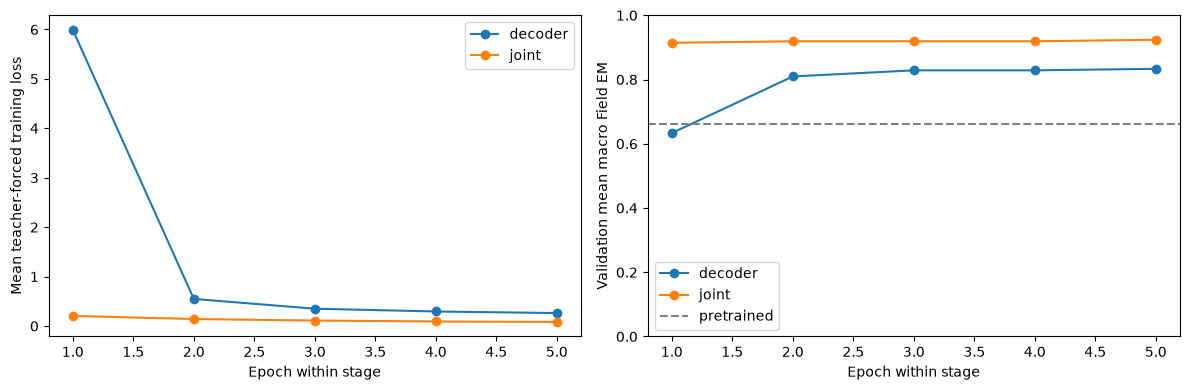

In [31]:
selected_model = load_model(selection["checkpoint"]).eval()
selected = evaluate_model(selected_model, "selected_reload")
columns = ["identity_key", "source", "field", "raw_prediction", "normalized_exact_match"]
pd.testing.assert_frame_equal(selected["fields"][columns], best_overall["fields"][columns], check_dtype=False)
assert abs(selected["selection_score"] - selection["selection_score"]) < 1e-12

comparison = baseline["fields"].merge(selected["fields"], on=["identity_key", "source", "field"],
                                       suffixes=("_pretrained", "_finetuned"), validate="one_to_one")
comparison["transition"] = np.select(
    [~comparison.normalized_exact_match_pretrained & comparison.normalized_exact_match_finetuned,
     comparison.normalized_exact_match_pretrained & ~comparison.normalized_exact_match_finetuned,
     comparison.normalized_exact_match_pretrained & comparison.normalized_exact_match_finetuned],
    ["fixed", "regressed", "still_correct"], default="still_wrong")
comparison.to_csv(artifact_directory / "prediction_transitions.csv", index=False)
transition_summary = comparison.groupby(["source", "field", "transition"], as_index=False).size()
transition_summary.to_csv(artifact_directory / "transition_summary.csv", index=False)
accuracy_comparison = pd.concat([baseline["summary"].assign(model="pretrained"), selected["summary"].assign(model="selected")], ignore_index=True)
accuracy_comparison.to_csv(artifact_directory / "accuracy_comparison.csv", index=False)
field_comparison = baseline["per_field"].merge(selected["per_field"], on=["source", "field"], suffixes=("_pretrained", "_finetuned"))
field_comparison.to_csv(artifact_directory / "per_field_comparison.csv", index=False)
display(accuracy_comparison)
display(field_comparison[["source", "field", "normalized_matches_pretrained", "normalized_matches_finetuned", "cer_pretrained", "cer_finetuned"]])
display(transition_summary)
display(comparison.loc[comparison.transition.isin(["regressed", "still_wrong"]),
    ["identity_key", "source", "field", "raw_ground_truth_pretrained", "raw_prediction_pretrained", "raw_prediction_finetuned", "transition"]])

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for stage_name, group in pd.DataFrame(history).groupby("stage", sort=False):
    axes[0].plot(group.epoch, group.training_loss, marker="o", label=stage_name)
    axes[1].plot(group.epoch, group.selection_score, marker="o", label=stage_name)
axes[0].set(xlabel="Epoch within stage", ylabel="Mean teacher-forced training loss")
axes[1].set(xlabel="Epoch within stage", ylabel="Validation mean macro Field EM", ylim=(0,1))
axes[1].axhline(baseline["selection_score"], linestyle="--", color="gray", label="pretrained")
for ax in axes: ax.legend()
fig.tight_layout()
fig.savefig(artifact_directory / "training_curves.png", dpi=140, bbox_inches="tight")
plt.show()

## 9.8 Compare warm latency under the same conditions

Measure original and selected weights in the same session using the `04c`
boundary: a preloaded canonical RGB card to normalized, validated seven-field
prediction. Inference sums seven synchronized `generate` calls. Loading,
rectification, reference scoring, and file writing remain outside the timer.
Same float32 precision, sequential crop batch size one, greedy decoding, and
disabled KV cache. Three warm-ups per source and three measured repetitions of
every observation give 90 timed requests per model.

Fine-tuning does not change architecture size. Latency may nevertheless change
because output token counts and stopping behavior change. That is measured, not
assumed. Repeated timings must reproduce their corresponding accuracy predictions.

In [32]:
def timed_request(model, observation):
    torch.cuda.synchronize(device)
    start = time.perf_counter()
    crops = extract_field_crops(observation, raw_to_canonical_field, field_crop_config)
    raw, inference_ms, token_count = {}, 0.0, 0
    for field, crop in crops.items():
        pixels = processor(images=crop["crop_rgb"], return_tensors="pt").pixel_values.to(device)
        torch.cuda.synchronize(device)
        inference_start = time.perf_counter()
        with torch.inference_mode():
            generated = model.generate(pixel_values=pixels, generation_config=generation)
        torch.cuda.synchronize(device)
        inference_ms += (time.perf_counter() - inference_start) * 1000
        ids = generated[0].detach().cpu().tolist()
        token_count += len(ids) - 1
        raw[field] = processor.decode(ids, skip_special_tokens=True, clean_up_tokenization_spaces=False)
    normalized = normalize_document_values(raw, required_field_names)
    validation = validate_document_values(normalized, required_fields=required_field_names, validation_config=alb_id_validation_config)
    torch.cuda.synchronize(device)
    end_to_end_ms = (time.perf_counter() - start) * 1000
    return raw, inference_ms, end_to_end_ms, token_count

del selected_model
release_memory()
latency_rows = []
for label, checkpoint, scored in [("pretrained", None, baseline), ("selected", selection["checkpoint"], selected)]:
    model = load_model(checkpoint).eval()
    expected = {(identity, source): dict(zip(group.field, group.raw_prediction))
                for (identity, source), group in scored["fields"].groupby(["identity_key", "source"])}
    for source in experiment["sources"]:
        for identity in validation_keys[:experiment["latency"]["warmup_documents_per_source"]]:
            raw, _, _, _ = timed_request(model, validation_observations[(identity, source)])
            assert raw == expected[(identity, source)]
    rng = np.random.default_rng(experiment["seed"])
    keys = list(validation_observations)
    for repetition in range(experiment["latency"]["repetitions_per_observation"]):
        for position, index in enumerate(rng.permutation(len(keys))):
            key = keys[int(index)]
            raw, inference_ms, end_to_end_ms, token_count = timed_request(model, validation_observations[key])
            assert raw == expected[key]
            assert end_to_end_ms >= inference_ms > 0
            latency_rows.append({"model": label, "identity_key": key[0], "source": key[1],
                "repetition": repetition, "order_position": position, "inference_ms": inference_ms,
                "end_to_end_ms": end_to_end_ms, "generated_tokens": token_count})
    del model
    release_memory()
latency = pd.DataFrame(latency_rows)
assert len(latency) == 180 and latency.groupby(["model", "identity_key", "source"]).size().eq(3).all()
latency_summary = latency.groupby(["model", "source"], as_index=False).agg(
    requests=("inference_ms", "size"), inference_mean_ms=("inference_ms", "mean"),
    inference_median_ms=("inference_ms", "median"), end_to_end_mean_ms=("end_to_end_ms", "mean"),
    end_to_end_median_ms=("end_to_end_ms", "median"), end_to_end_std_ms=("end_to_end_ms", "std"),
    mean_generated_tokens=("generated_tokens", "mean"))
latency.to_csv(artifact_directory / "latency_measurements.csv", index=False)
latency_summary.to_csv(artifact_directory / "latency_summary.csv", index=False)
display(latency_summary)

Loading weights:   0%|          | 0/360 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 360/360 [00:00<00:00, 16014.74it/s]


[transformers] VisionEncoderDecoderModel LOAD REPORT from: microsoft/trocr-small-printed
Key                         | Status  | 
----------------------------+---------+-
encoder.pooler.dense.bias   | MISSING | 
encoder.pooler.dense.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Loading weights:   0%|          | 0/362 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 362/362 [00:00<00:00, 20120.03it/s]

,model,source,requests,inference_mean_ms,inference_median_ms,end_to_end_mean_ms,end_to_end_median_ms,end_to_end_std_ms,mean_generated_tokens
0,pretrained,photo,45,273.053852,272.890151,280.942730,280.672690,3.658096,35.266667
1,pretrained,template,45,265.780958,265.824844,273.642152,273.610682,4.493563,33.133333
2,selected,photo,45,288.607138,288.740814,296.591875,296.637022,3.643666,40.133333
3,selected,template,45,289.095866,288.766045,297.129284,296.716687,3.860546,40.266667


## 9.9 Inspect remaining errors and record the outcome

The gallery includes remaining errors and regressions, using exactly the crop
provided to the recognizer. A successful nationality score is reported alongside
the nonconstant-field score to expose the constant-target caveat. Training-set
loss curves and the eight-example sanity check are not accuracy estimates.

We keep the original baseline, both stage-best checkpoints, configuration,
data/exclusion manifest, optimizer/epoch histories, all candidate predictions,
selected-checkpoint hashes, reload verification, and repeat timings. Model weights
and raw artifacts remain local in ignored directories; the executed notebook,
configuration, learning notes, and report are repository artifacts.

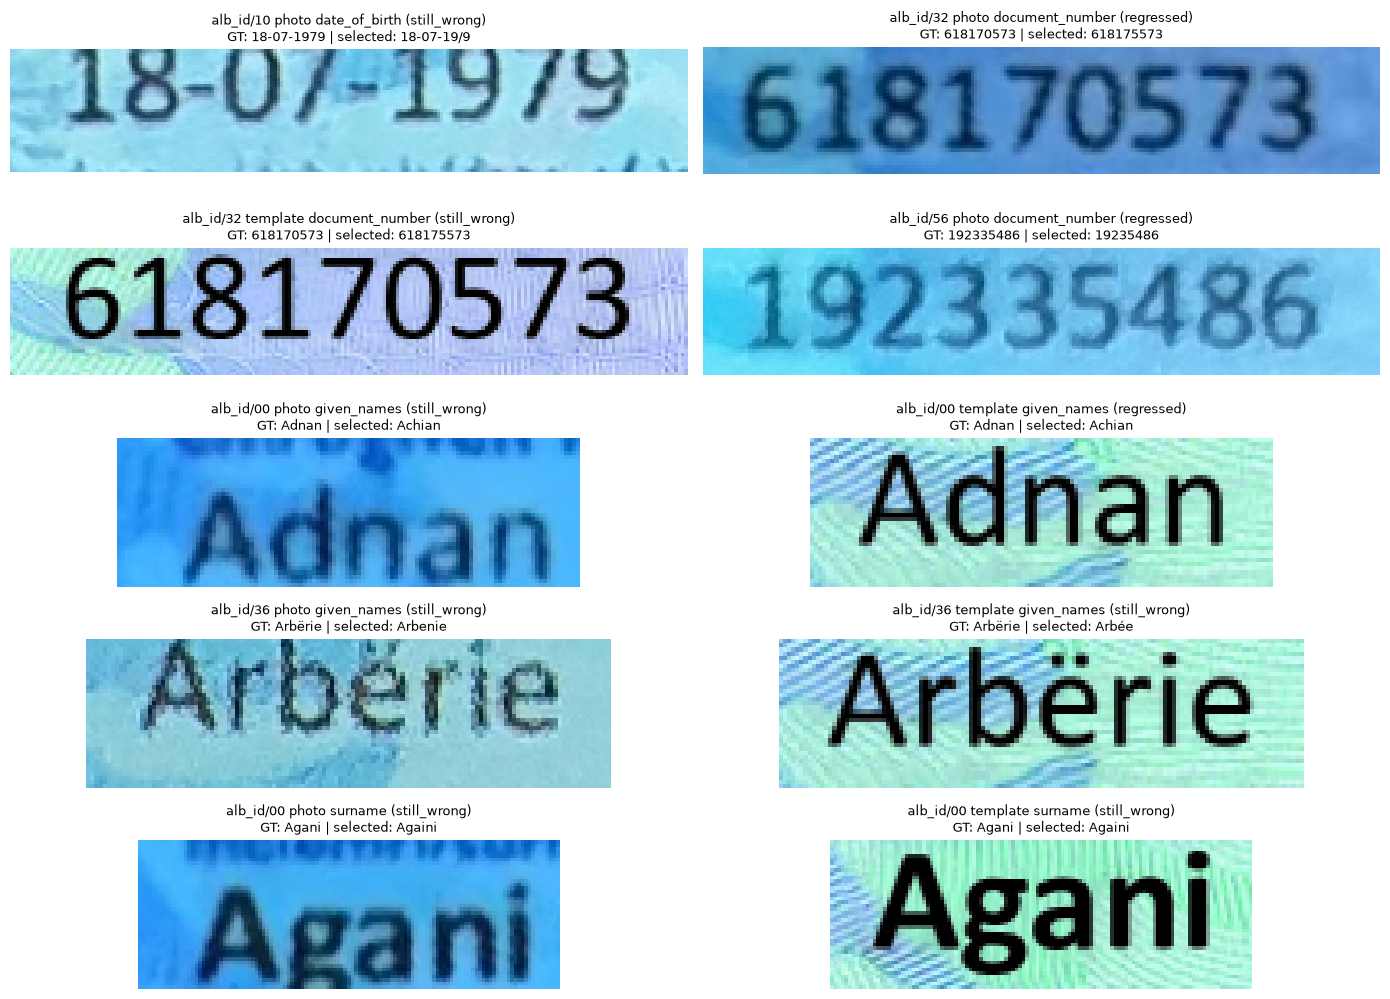

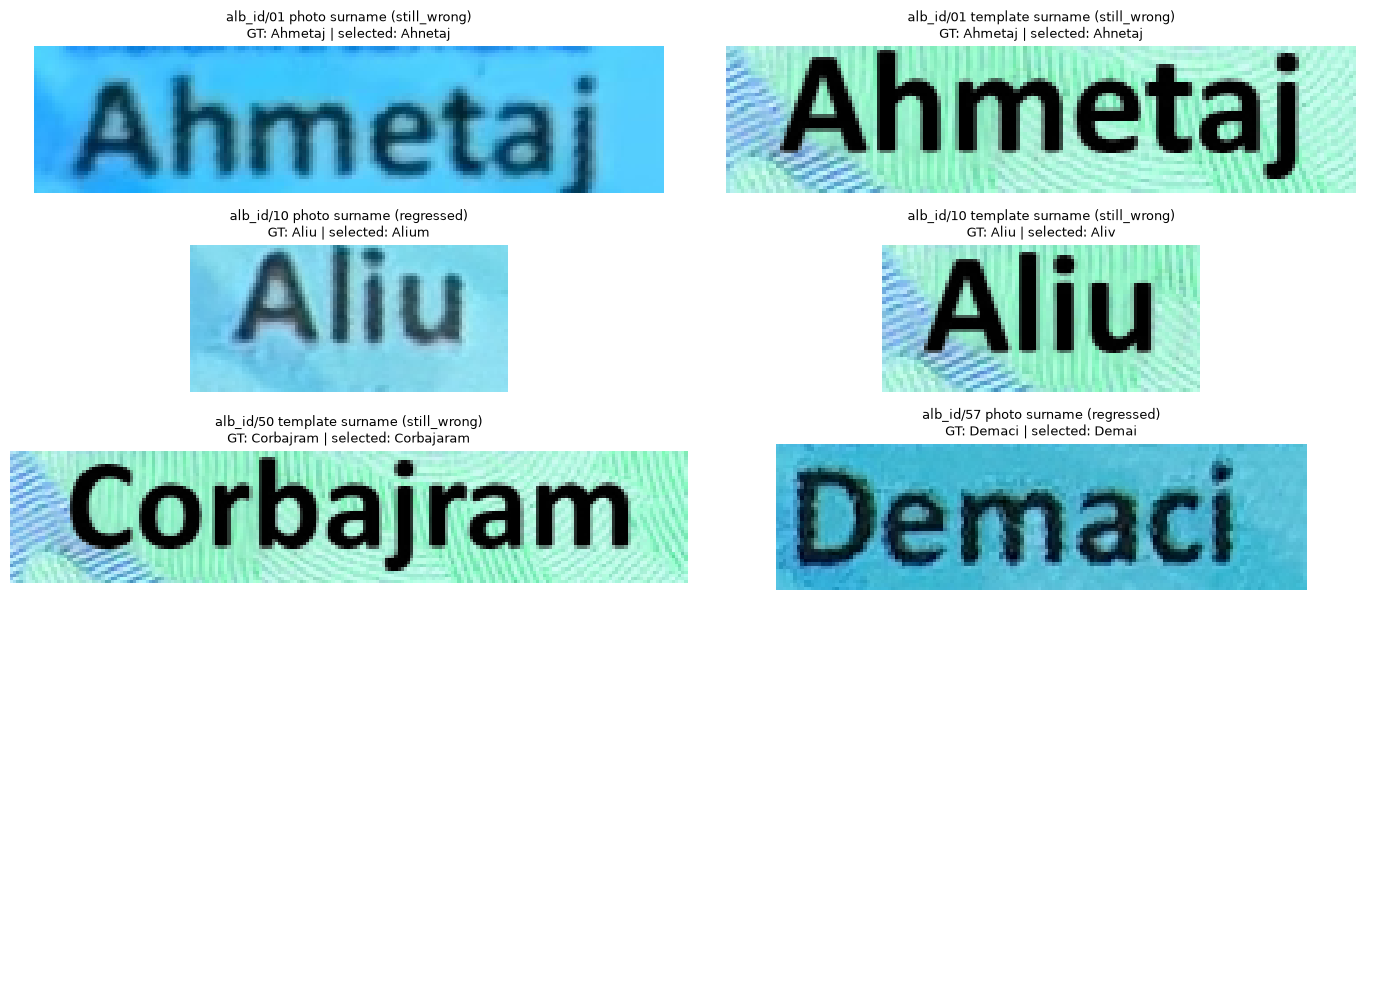

,model,source,correct,samples,field_em
0,pretrained,photo,76,90,0.844444
1,pretrained,template,63,90,0.700000
2,selected,photo,81,90,0.900000
3,selected,template,83,90,0.922222


Completed experiment: 20261012T230738117335Z
Selected checkpoint: /home/raspiestchip/kyc-router/checkpoints/phase3_finetuning/20261012T230738117335Z/joint/best
Phase 3 is still open.


In [33]:
remaining = comparison.loc[~comparison.normalized_exact_match_finetuned].sort_values(["field", "identity_key", "source"])
crop_cache = {key: extract_field_crops(obs, raw_to_canonical_field, field_crop_config)
              for key, obs in validation_observations.items()}
for start in range(0, len(remaining), 10):
    page = remaining.iloc[start:start+10]
    fig, axes = plt.subplots(5, 2, figsize=(14, 10))
    for ax in axes.flat: ax.axis("off")
    for ax, row in zip(axes.flat, page.itertuples()):
        ax.imshow(crop_cache[(row.identity_key, row.source)][row.field]["crop_rgb"])
        ax.set_title(f"{row.identity_key} {row.source} {row.field} ({row.transition})\nGT: {row.raw_ground_truth_pretrained} | selected: {row.raw_prediction_finetuned}", fontsize=9)
    fig.tight_layout()
    fig.savefig(artifact_directory / f"remaining_failures_{start//10+1:02d}.png", dpi=120, bbox_inches="tight")
    plt.show()

nonconstant_comparison = pd.DataFrame([
    {"model": name, "source": source, "correct": int(group.normalized_exact_match.sum()),
     "samples": len(group), "field_em": float(group.normalized_exact_match.mean())}
    for name, result in [("pretrained", baseline), ("selected", selected)]
    for source, group in result["fields"].loc[result["fields"].field != "nationality"].groupby("source")])
nonconstant_comparison.to_csv(artifact_directory / "nonconstant_accuracy.csv", index=False)
display(nonconstant_comparison)
weight_hashes = {}
if selection["checkpoint"] is not None:
    weight_hashes = {path.name: file_hash(path) for path in sorted(Path(selection["checkpoint"]).iterdir()) if path.is_file()}
findings = {
    "run_id": run_id, "phase3_status": "open; closure pending joint review", "selection": selection,
    "baseline_accuracy": baseline["summary"].to_dict(orient="records"),
    "selected_accuracy": selected["summary"].to_dict(orient="records"),
    "nonconstant_accuracy": nonconstant_comparison.to_dict(orient="records"),
    "latency": latency_summary.to_dict(orient="records"),
    "transitions": comparison.transition.value_counts().to_dict(),
    "remaining_failures": len(remaining), "checkpoint_files_sha256": weight_hashes,
    "sanity_passed": True, "checkpoint_reload_passed": True, "latency_prediction_repeats_passed": True,
}
save_json(artifact_directory / "findings.json", findings)
print("Completed experiment:", run_id)
print("Selected checkpoint:", selection["checkpoint"])
print("Phase 3 is still open.")

### Reading the remaining failures

Both gallery pages were visually reviewed for this recorded run. The expected
text is inside the crop boundaries: 12 remaining name errors, three document
numbers, and one birth date. Photos are softer, but readable templates also fail;
capture degradation alone is not an adequate explanation.

`Ahmetaj → Ahnetaj` appears in both sources. `Arbërie` remains wrong although its
target passes tokenizer round-trip checks: encoding a character and recognizing
it are different capabilities. The number `618170573 → 618175573` substitutes a
digit in both sources, while photo `192335486` loses one. The date's `7 → /`
remains wrong as it was pretrained. These are observations, not proof of a
specific attention or decoder failure mechanism.

Fourteen of the 16 wrong fields pass the semantic validator. Only the malformed
date and eight-digit number are rejected. Most importantly, two formerly correct
photo document numbers regressed: that field went from 15/15 to 13/15 despite
the aggregate gain. No model switching, lookup correction, or normalization
change hides these cases. Candidate adoption should consider field importance,
not just macro accuracy.

Same-session median end-to-end latency rose from 273.61 to 296.72 ms for
templates, and 280.67 to 296.64 ms for photos. Selected outputs require about
40 generated tokens per document rather than 33–35, consistent with additional
decoding work. Timing order was not counterbalanced, so this is not a causal
isolation of token count or a concurrent-service benchmark.

The experiment completed its planned five epochs per stage. The final epoch
added one correct field after a near plateau; this does not establish globally
optimal settings or prove convergence. All 33 code cells executed without error;
independent serialized-score replay, split checks, finite-gradient checks,
selection ordering, accumulation-tail checks, and checkpoint hashes also passed.
See the [report](../docs/experiments/ocr-finetuning.md) for the verification record.

These annotations describe run `20261012T230738117335Z`; rerunning code creates a
new run and requires a fresh result interpretation. Phase 3 remains open.


## Interpretation of this recorded run

Run `20261012T230738117335Z` selected **joint_epoch_05**. Mean validation macro
Field EM rose from **66.19%** to **92.38%**. There were
**60 fixed fields**, **5 regressions**, and **16 remaining
errors**. The selected checkpoint reload and all 180 timing-prediction checks
passed. Training/selection took **15.3 minutes** within the
one-hour budget.

| Model | Source | Normalized fields / macro EM | CER | Document EM | Raw matches |
|---|---|---|---|---|---|
| Pretrained | template | 63/105 (60.00%) | 17.34% | 0/15 (0.00%) | 43/105 |
| Pretrained | photo | 76/105 (72.38%) | 5.05% | 0/15 (0.00%) | 55/105 |
| Selected | template | 98/105 (93.33%) | 1.21% | 9/15 (60.00%) | 98/105 |
| Selected | photo | 96/105 (91.43%) | 1.87% | 8/15 (53.33%) | 96/105 |

The per-epoch history illustrates why we select generated validation metrics,
not the last epoch or lowest training loss. The detailed
[report](../docs/experiments/ocr-finetuning.md) records the remaining-error visual review,
nonconstant-field comparison, latency tradeoff, exact candidate path, and limits.
The model is an experiment candidate for joint review; Phase 3 remains open.


## Handoff and learning review

The [experiment report](../docs/experiments/ocr-finetuning.md) interprets the observed
results, errors, limitations, and checkpoint recommendation. Workshop 10 remains
pending. No test images were read and no Phase 4 work was started.

Review: trace one crop into pixels, labels, shifted decoder inputs, token loss,
gradients, optimizer update, generated prediction, and normalized metric. Explain
why padding is ignored, why tiny-set memorization is useful only as a diagnostic,
why generation is needed for validation, and why nationality alone is inadequate
evidence of general recognition. Explain the cost of gradient checkpointing and
why a faster or slower result after fine-tuning can occur without changing the
architecture. These prompts remain learning tasks for the reader.

## Workshop 10 — Freeze and extract the OCR pipeline

The user authorized Phase 3 closure after the fine-tuning and resource reports.
We adopt `joint_epoch_05` under the original macro Field EM objective, accepting
and documenting the photo document-number regression from 15/15 to 13/15.
No extra training, per-field fallback, new scoring rule, test evaluation, or
profiling optimization is introduced here.

The reusable package now receives **canonical pixels + seven rectangles**.
Unlike the research helpers above, inference does not require or carry ground
truth. References are passed separately to `score_document`. Stateless steps are
functions; one concrete `OcrPipeline` keeps the expensive model loaded. This is
ordinary composition, not a generic pipeline framework.

See the [delivery record](../docs/phases/phase-3.md),
[architecture](../docs/architecture.md), and
[usage guide](../docs/guides/ocr-usage.md) for the frozen behavior and actual API.
The independent GPU check compared 210 crop bytes, 210 raw strings/token
sequences, normalized scores/validators, and 90 timed repeats. The cell below
reads and verifies that evidence; it does **not** retrain or rerun inference.

Earlier `Phase 3 remains open` statements are historical experiment handoffs.
The training policy and candidate manifest remain unchanged; the separate
`ocr_pipeline_v1.json` records the subsequent adoption. Run All still performs
the original training experiment, so read its reproduction instructions first.


In [1]:
from pathlib import Path
import hashlib
import json

import pandas as pd

from kyc_router.ocr import OcrPipeline, load_pipeline

phase3_working_directory = Path.cwd().resolve()
phase3_root = (
    phase3_working_directory
    if (phase3_working_directory / "PROJECT.md").is_file()
    else phase3_working_directory.parent
)
phase3_manifest_path = phase3_root / "configs/ocr_pipeline_v1.json"
phase3_manifest = json.loads(phase3_manifest_path.read_text(encoding="utf-8"))
phase3_verification_path = (
    phase3_root / "outputs/phase3_closure/20261013T004540259201Z/verification.json"
)
if not phase3_verification_path.is_file():
    raise FileNotFoundError("Restore the closure artifacts or run experiments.verify_ocr_source.")
phase3_verification = json.loads(phase3_verification_path.read_text(encoding="utf-8"))
assert hashlib.sha256(phase3_manifest_path.read_bytes()).hexdigest() == phase3_verification["pipeline_manifest_sha256"]
for phase3_relative_path, phase3_expected_hash in phase3_verification["source_files_sha256"].items():
    assert hashlib.sha256((phase3_root / phase3_relative_path).read_bytes()).hexdigest() == phase3_expected_hash
assert phase3_verification["geometry_crop_parity_checks"] == 210
assert phase3_verification["raw_prediction_and_token_parity_checks"] == 210
assert phase3_verification["timing_repeats_with_exact_prediction_and_token_agreement"] == 90
assert not phase3_verification["test_evaluated"]
assert phase3_manifest["final_pipeline_freeze"]
print("Phase 3 closed; adopted:", phase3_manifest["selection"]["candidate"])
print("Source API:", OcrPipeline.__name__ + ".extract(canonical_rgb, rectangles)")
print("\nValidation accuracy:")
print(pd.DataFrame(phase3_verification["summary"])[
    ["source", "normalized_matches", "field_samples", "macro_field_em", "cer", "document_matches"]
].to_string(index=False))
print("\nSource verification latency:")
print(pd.DataFrame(phase3_verification["latency"])[
    ["source", "requests", "end_to_end_mean_ms", "end_to_end_median_ms"]
].to_string(index=False))


/home/raspiestchip/kyc-router/.venv/lib64/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Phase 3 closed; adopted: joint_epoch_05
Source API: OcrPipeline.extract(canonical_rgb, rectangles)

Validation accuracy:
  source  normalized_matches  field_samples  macro_field_em      cer  document_matches
   photo                  96            105        0.914286 0.018661                 8
template                  98            105        0.933333 0.012075                 9

Source verification latency:
  source  requests  end_to_end_mean_ms  end_to_end_median_ms
   photo        45          286.859142            286.048060
template        45          287.162271            287.206757


### Learning review and next boundary

Engineering checks do not certify understanding. These remain useful notebook
reflection prompts, not assessments silently marked as passed:

1. Trace one image through geometry, crop bytes, processed tensors, encoder,
   decoder tokens, raw text, normalization, validation, and scoring.
2. Why must the runtime not read the reference transcription? Why is a
   nine-digit, semantically valid number still potentially wrong?
3. Why is the model loaded once? Why use both evaluation mode and inference
   mode? What do synchronization and timer boundaries actually measure?
4. Which changes require rerunning validation or creating a new contract/model
   version? Why must old reports, checkpoints, and audit snapshots be retained?
5. Explain the adoption tradeoff, including the constant-nationality diagnostic
   and document-number regressions, without using only the aggregate score.

**Phase 3 engineering delivery is complete. Test remains sealed.** Phase 4,
routers, synthetic benchmark sweeps, serving, and distributed infrastructure are
not implemented by this closure.
